## Линейная регрессия

Одним из важных алгоритмов машинного обучения является **линейная регрессия**. Рассмотрим постановку задачи, а также разберём алгоритм на практических примерах

**Линейная регрессия** - способ найти линейную зависимость (в случае трёхмерного пространства, например, это будет плоскость), которая лучше всего описывает связь между разными величинами.

С помощью линейной регрессии можно решать большое количество задач, например:
- прогноз числовых значений
- поиск главных факторов
- определение трендов
- проверка идей

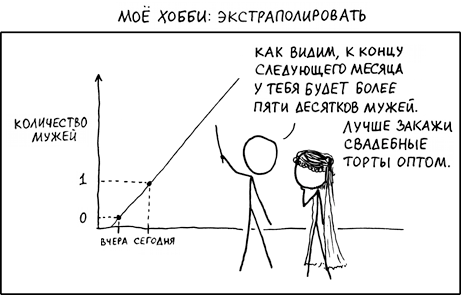

Прежде, чем использовать названный метод, необходимо проверить тот факт, что обучающие данные действительно представляют линейную зависимость. Если же связь будет носить более сложный характер, то линейная регрессия будет ошибаться.

### Постановка задачи и описание модели

Простейший пример постановки задачи линейной регрессии - **метод наименьших квадратов** (ordinary least squares, OLS).
Пусть задана некоторая зависимость объясняемой (целевой) переменной от объясняющих её факторов. В случае рассматриваемой задачи такая зависимость будет линейной, запишем её в виде математической формулы:
$$\large y_i = \omega_0 + \sum_{i=1}^{d}{\omega_ix_i} + \epsilon_i, $$ где $y$ - объясняемая переменная, $x_i$ - объясняющий фактор (другими словами, известные данные или наблюдения), $w_i$ - коэффициенты (веса), $w_0$ - свободный член, $\epsilon_i$ - случайная непрогнозируемая ошибка.

Если добавить в наблюдения фиктивную размерность $x_0$, тогда предыдущую формулу можно будет записать в более компактном виде, записав свободный член под суммой:
$$\large y_i = \sum_{i=0}^{d}{\omega_ix_i} + \epsilon_i = \vec{\omega}^T\vec{x} + \epsilon_i$$
Если мы будем рассматривать матрицу наблюдений-признаков $X$, то в таком случае необходимо будет добавить единичный столбец слева, и запись примет следующий вид:
$$\large \vec{y} = X\vec{\omega} + \epsilon,$$
где
- $\vec{y} \in \mathbb{R}^n$ - вектор прогнозируемой переменной
- $\vec{\omega}$ - вектор параметров модели
- $X$ - матрица наблюдений и признаков, каждая строка представляет отдельные наблюдения, слева дописан единичный столбец, имеет размерность $n \times (d + 1)$, где $n$ - число наблюдлений, а $d$ - число признаков
- $\epsilon$ - случайная ошибка модели

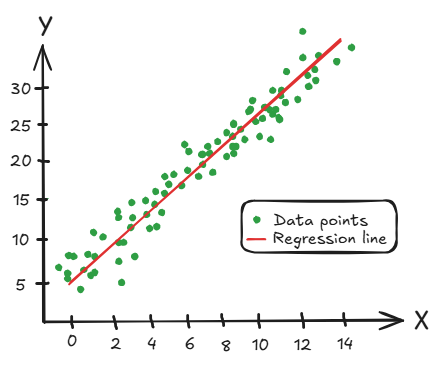

Таким образом, мы хотим найти функцию, которая будет "лучшим" образом приближать зависимость между целевой переменной и наблюдениями. Понятие "лучшим" требует формализации, иначе не совсем понятно в каком смысле оно применяется. Простыми словами, мы должны научиться каким-то образом измерять качество полученной модели (функции) и минимизировать её ошибку, изменяя некоторым образом обучаемые параметры (веса). Функция оценивающая ошибки модели, традиционно называется функцией потерь, функционалом качества или лоссом (англ. loss function). Интуитивно понятно, что для текущей задачи нам необходимо взять предсказание нашей модели и каким-то образом сравнить его с истинными значениями. Важно, чтобы эту функцию было возможно оптимизировать, т.е. она должна быть гладкой, а не кусочной, чтобы можно было применять, например, алгоритм градиентного спуска. Так как векторы предсказаний и целевых значений находятся в одном векторном пространстве, то целесообразно в качестве функции потерь использовать расстояние между ними. Однако, способов задать расстояние между двумя векторами в пространстве довольно много, поэтому остановимся на 
сумме квадратов ошибок или **среднеквадратическом отклонении** (Mean Squared Error, MSE). 


Функция потерь задаётся следующим образом:

$$\large \begin{array}{rcl}\mathcal{L}\left(\textbf{X}, \textbf{y}, \textbf{w} \right) &=& \frac{1}{2n} \sum_{i=1}^n \left(y_i - \textbf{w}^{\text{T}} \textbf{x}_i\right)^2 \\
&=& \frac{1}{2n} \left\| \textbf{y} - \textbf{X} \textbf{w} \right\|_2^2 \\
&=& \frac{1}{2n} \left(\textbf{y} - \textbf{X} \textbf{w}\right)^{\text{T}} \left(\textbf{y} - \textbf{X} \textbf{w}\right)
\end{array}$$

Стоит отметить, что множитель $\frac{1}{2n}$ перед суммой выполняет важную функцию: в случае его отсутствия, невозможно было бы сравнивать ошибку модели на выборках данных разной размерности, так как получаемые результаты не были бы масштабированы.

Теперь для каждой конкретной линейной функции, которая задаётся весами, мы получаем число, которое оценивает насколько точно наша модель приближает значения объясняемой переменной. Чем меньше будет это число (ошибка), тем точнее наша функция будет описывать зависимость. Тогда, чтобы найти лучшую модель, нам необходимо минимизировать функцию потерь по параметрам $\omega$. Задача сводится к минимизации функции потерь:

$$\large \left\| \textbf{y} - \textbf{X} \textbf{w} \right\|_2^2 \to \min_{\omega}$$    

Более подробно попытаемся обосновать, почему в качестве функции потерь используется сумма квадратов ошибок, решим поставленную задачу.

### Метод наименьших квадратов

#### Ограничения

Чтобы применение модели линейной регрессии было возможно для конкрентной задачи, необходимо соблюдение ряда ограничений, вытекающих из теоремы [Гаусса-Маркова](https://ru.wikipedia.org/wiki/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D0%BC%D0%B0_%D0%93%D0%B0%D1%83%D1%81%D1%81%D0%B0_%E2%80%94_%D0%9C%D0%B0%D1%80%D0%BA%D0%BE%D0%B2%D0%B0).

1. $y = \vec{\omega}^T\vec{x} + \epsilon$, т.е. модель состоит из фиксированной части ($y = \vec{\omega}^T\vec{x}$) и случайной части ($\epsilon$), модель *линейна по параметрам* (важно, что модель должна быть линейной именно по параметрам, а не наблюдениям, так как например использование квадрата признака является одним из приёмом feature engineering).
2. все $x_i$ детерменированы и не все равны между собой, иными словами, переменные не должны быть постоянными.
3. $\operatorname{rank} X = d + 1$, т.е. отсутствие мультиколлинеарности в данных (популярным примером мультиколлинеарности является наличие составного признака, приблизительно совпадающего с суммой двух других)
4. $\forall{i}: \mathbb{E}[\epsilon_{i}] = 0$, матожидание случайных ошибок равно нулю, не должно быть причины для того, чтобы случайный член порождал бо́льшую ошибку в одних наблюдениях, чем в других.
5. $\forall i \neq j: \operatorname{Cov}(\epsilon_i, \epsilon_j) = 0$, случайные ошибки не скоррелированы.

Из этих свойств следует, что получаемая с помощью МНК (метода наименьших квадратов) оценка является несмещённой $\mathbb{E}[\hat{\vec{\omega}}] = \vec{\omega}$.

Добавим ещё одно ограничение, называемое *гомоскедатичностью* в нашу систему:

6. $\forall i: \text{Var}\left(\epsilon_i\right) = \sigma^2 < \infty$, дисперсия случайных ошибок одинакова и конечна.

Из полученной системы ограничений, накладываемых на модель следует, что МНК даёт оценку максимального правдоподобия (Maximum Likelihood Estimation), следовательно при использовании МНК дисперсия несмещённой оценки будет минимальной $\text{Var}
\left(\hat{\vec{\omega}}\right) \to \min$.

Определим также формально используемые при объяснении термины из математической статистики.

Каждый элемент выборки независимых одинаково распределенных случайных величин (i.i.d) $X_1,…,X_n$ можно рассматривать как значение случайной величины из некоторого распределения с неизвестным параметром $\theta$.

Всякую оценку этого параметра $\hat{\theta}(X_1,…,X_n)$ можно также считать случайной величиной.

*Опр 1.* Оценка $\hat{\theta}(X_1,…,X_n)$ параметра $\theta$ называется несмещённой, если $\mathbb{E}[\hat{\theta}] = \theta$. Несмещённость оценки означает, что она в среднем будет равна истинному значению параметра.

*Опр 2.* Оценка $\hat{w_i}$ весов $w_i$ называется линейной, если:
$$\large \hat{w_i} = w_{1i}y_1 + w_{2i}y_2 + \dots + w_{1n}y_n$$


#### Вывод

##### Метод наименьших квадратов: точный аналитический метод


##### Способ 1. Геометрический

Воспользуемся геометрическим подходом для решения задачи оптимизации.

Пусть $x^{(1)}, x^{(2)}, \dots, x^{(D)}$ - столбцы матрицы наблюдений $X$, т.е. столбцы признаков.
Тогда

$$X\omega = \omega_1x^{(1)} + \omega_2x^{(2)} + \dots + \omega_Dx^{(D)}$$

Теперь найдём линейную комбинацию столбцов $x^{(1)}, x^{(2)}, \dots, x^{(D)}$, которая наилучшим способов приближает $y$ по евклидовой норме, т.е. найдём проекцию вектора $y$ на подпространство, заданное векторами $x^{(1)}, x^{(2)}, \dots, x^{(D)}$. 
Тогда вектор $y$ можно разложить на две состовляющие $y = y_{\parallel} + y_{\bot}$, где $y_{\parallel} = X\omega$. Тогда по свойству скалярного произведения ортогональных векторов получим:
$$y_{\bot} = y - X\omega$$
Из вышесказанного свойства следует:
$$X^T(y - X\omega) = 0$$

Каждый элемент столбца $X^T(y - X\omega)$ - это скалярное произведение одного из столбцов $x^{(i)}$ на $y - X\omega$, т.е. на ортогональную составлябщую вектора $y$.

Получаем 

$$\omega = (X^TX)^{-1}X^Ty$$

##### Способ 2

Мини-шпаргалка по матричным производным:

$$\begin{array}{rcl} 
\frac{\partial}{\partial X}X^TA &=& A \\
\frac{\partial}{\partial X}X^TAX &=& (A + A^T)X \\
\frac{\partial}{\partial X}X^TAy &=& X^Ty \\
\frac{\partial}{\partial X}A^{-1} &=& -A^{-1}\frac{\partial A}{\partial X}A^{-1}
\end{array}$$

Минимизируем функцию потерь, для этого найдём градиент по вектору весов и приравняем к нулю, решим полученное уравнение относительно $\omega$:

$$\mathcal{L}\left(\textbf{X}, \textbf{y}, \omega\right) = \frac{1}{2n}\left\|\textbf{y} - \textbf{X} \textbf{w}\right\|_2^2 =\frac{1}{2n}(y - X\omega)^T(y - X\omega)$$

$$\frac{\partial \mathcal{L}}{\partial \omega} = \frac{\partial}{\partial \omega}\frac{1}{2n}\left(y^Ty - 2y^TX\omega + \omega^TX^TX\omega \right) = \frac{1}{2n}(-2X^Ty + 2X^TX\omega)$$

$$\begin{array}{rcl} \frac{\partial \mathcal{L}}{\partial \omega} = 0 &\Leftrightarrow& X^TX\omega - X^Ty = 0 \\
&\Leftrightarrow& X^TXw = X^Ty \\
&\Leftrightarrow& w = (X^TX)^{-1}X^Ty
\end{array}$$

##### Проблемы точного решения

Точное решение обладает рядом недостатков которые существенно влияют на программирование алгоритма линейной регрессии:
1. Вычислительная эффективность $O(D^2N + D^3)$, где $N$ - длина выборки, $D$ - число признаков. Слагаемое $D^2N$ отвечает за сложность перемножения матриц $X^T$ и $X$, а слагаемое $D^3$ - за сложность их обращения.
2. Мультиколиинеарность в данных. Для вычисления ответа нам необходимо обращать матрицу $X^TX$, и если между столбцами данных существует линейная зависимость, то матрица становится вырожденной, и тогда предложенный метод становится нерабочим. Аналогично, может существовать приближённая линейная зависимость между данными, тогда матрица $X^TX$ будет близка к вырожденной, решение становится неустойчивым: малые изменения в $y$ могут приводить к большим колебаниям весов $\omega$.

Эти проблемы не являются причиной не использовать такой метод. Существует несколько способов, позволяющих бороться с указанными проблемами.

#### Метод наименьших квадратов: приближенный численный метод.

Как уже упоминалось **функция потерь** является гладкой и выпуклой, а значит можно эффективно искать её функцию минимума с помощью итеративных градиентных методов.

Градиент функции в точке направлен в сторону её наискорейшего возрастания, следовательно антиградиент (противоположный градиенту вектор) в этой же точке направлен в сторону наискорейшего убывания. Имея некоторое приближение значения параметра к оптимальному, мы можем улучшить его, посчитав градиент функции потерь в точке и немного сдвинуть вектор весов в направлении антиградиента:

$$w'_j \rightarrow w_j - 
\alpha \frac{\partial}{\partial w_j}\mathcal{L}(X, y, \omega)$$
$\alpha$ - параметр алгоритма (темп обучения), который контролирует ту самую величину шага в сторону антиградиента. Описанный алгоритм называется **градиентным спуском**.

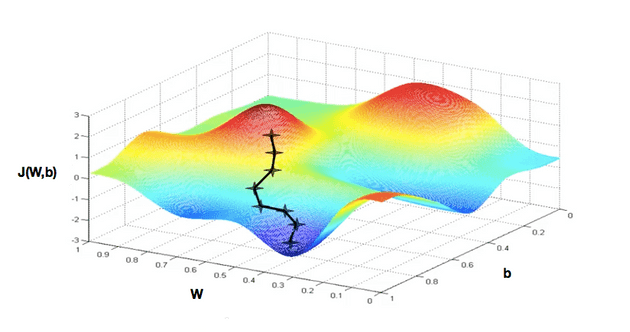

Выведем решение для предложенного алгоритма:

$$\large
\begin{equation*}
\begin{cases}
\hat{y_1} = \omega_0 + \omega_1x_{11} + \omega_2x_{12} + \dots + \omega_dx_{1d} \\
\hat{y_2} = \omega_0 + \omega_1x_{21} + \omega_2x_{22} + \dots + \omega_dx_{2d} \\
\dots \\
\hat{y_n} = \omega_0 + \omega_1x_{n1} + \omega_2x_{n2} + \dots + \omega_dx_{nd} 
\end{cases}
\end{equation*}
$$,

где:
- $\omega_{0,\dots,d} - признаки$
- $x_{1,\dots,m}$ - наблюдения
- $y$, объясняемая переменная
- $\hat{y}$ - предсказанное значение

Запишем функцию потерь в следующем виде:

$$\large\mathcal{L}(X,y,\omega) = \frac{1}{2n}\sum_{i=1}^{n}(
\hat{y_i} - y_i)^2$$

Вычислим градиент от $\mathcal{L}$ по $\omega$:

$$\large
\nabla{\mathcal{L}} =
\begin{pmatrix}
\frac{\partial \mathcal{L}}{\partial \omega_1} \\
\frac{\partial \mathcal{L}}{\partial \omega_2} \\
\vdots \\
\frac{\partial \mathcal{L}}{\partial \omega_d}
\end{pmatrix}
=
\begin{pmatrix}
\frac{1}{n}\sum_{i=1}^{n}(\omega_0 + \omega_1x_{i1} + \omega_2x_{i2} - y_i) \\
\frac{1}{n}\sum_{i=1}^{n}(\omega_0 + \omega_1x_{i1} + \omega_2x_{i2} - y_i)x_{i1} \\
\vdots \\
\frac{1}{n}\sum_{i=1}^{n}(\omega_0 + \omega_1x_{i1} + \omega_2x_{i2} - y_i)x_{id}
\end{pmatrix}
$$

Воспользуемся ранее описанным методом, а именно добавим единичный столбкец в матрицу наблюдений, чтобы вычисление производной по каждому из $\omega_1, \dots, \omega_d$ было по одному и тому же шаблону.

Тогда производная по любой из переменных будет иметь вид

$$\large \frac{\partial \mathcal{L}}{\partial \omega_m} = \frac{1}{n}\sum_{i=1}^{n}(\omega_0 + \omega_1x_{i1} + \omega_2x_{i2} - y_i)x_{im}$$

Необходимо перемножить каждую ошибку на соответствующий экземпляр фичи и просуммировать их


$$\large
\nabla{\mathcal{L}} = 
\begin{pmatrix}
\theta_1 \\
\theta_2 \\
\vdots \\
\theta_d
\end{pmatrix} = 
\frac{1}{n}
\begin{pmatrix}
1 & 1 & 1 & \dots & 1 \\
x_{11} & x_{21} & x_{31} &  \dots & x_{n1}\\
x_{12} & x_{22} & x_{32} & \dots & x_{n2} \\
\vdots & \vdots & \ddots & \vdots & \vdots \\
x_{1m} & x_{2m} & x_{3m} & \dots x_{nm}
\end{pmatrix}
\begin{pmatrix}
\hat{y_1} - y_1 \\
\hat{y_2} - y_2 \\
\vdots \\
\hat{y_n} - y_n
\end{pmatrix}
$$

Или краткая запись:

$$
\underbrace{\mathbf{X}^{T}}_{d\times n}\cdot\underbrace{(\hat{\mathbf{y}}-\mathbf{y})}_{n\times 1}=\underbrace{\nabla_{\boldsymbol{\theta}}\mathcal{L}}_{d\times 1}
$$

Тогда

$$\large
\begin{pmatrix}
\omega_1 \\
\omega_2 \\
\vdots \\
\omega_d
\end{pmatrix}^{k+1} = 
\begin{pmatrix}
\omega_1 \\
\omega_2 \\
\vdots \\
\omega_d
\end{pmatrix}^k - \alpha
\begin{pmatrix}
\theta_1 \\
\theta_2 \\
\vdots \\
\theta_d
\end{pmatrix}^k$$, 
где $k$-шаг итерации, $\alpha$ - размер шага или темп обучения (learning rate) 